<a href="https://colab.research.google.com/github/rivindu02/EN3160-Image-Processing-and-Computer-Vision/blob/main/Assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
from skimage.feature import blob_log
from math import sqrt
import matplotlib.pyplot as plt

# Set matplotlib to display plots inline
%matplotlib inline

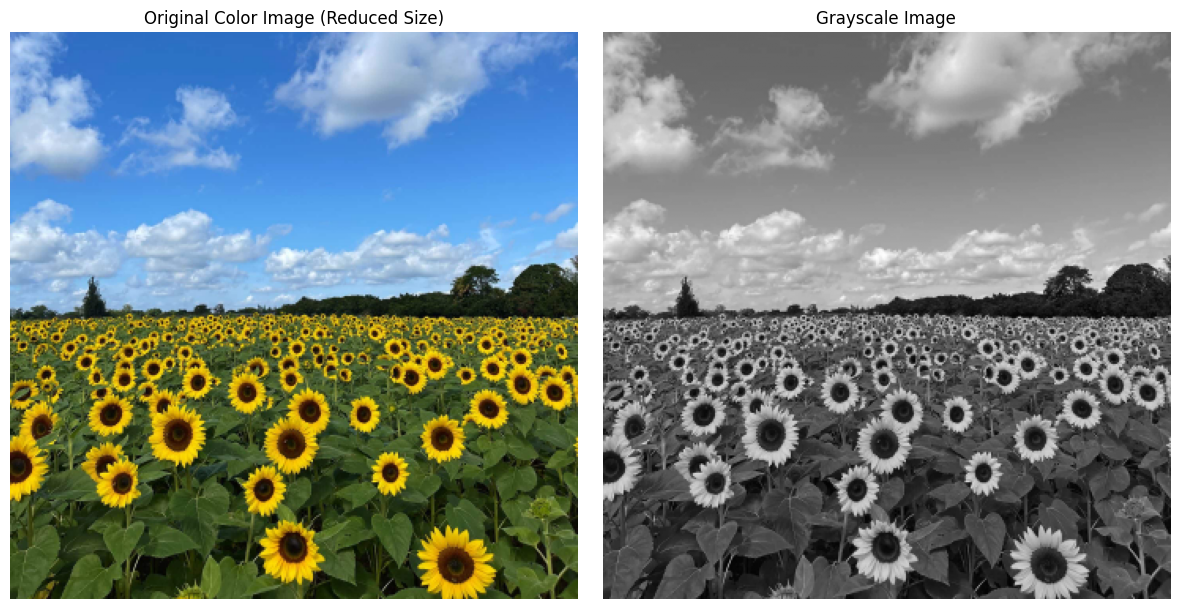

In [3]:
# Load the image at a reduced size (1/4)
# Make sure this path is correct!
image_path = 'the_berry_farms_sunflower_field.jpeg'
image = cv2.imread(image_path, cv2.IMREAD_REDUCED_COLOR_4)

# --- Error Check ---
if image is None:
    print(f"Error: Could not load image from path: {image_path}")
    print("Please ensure the image file is in the correct directory.")
else:
    # Convert the image to grayscale for blob detection
    image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Display the original and grayscale images
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    ax = axes.ravel()
    ax[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Original Color Image (Reduced Size)")
    ax[1].imshow(image_gray, cmap='gray')
    ax[1].set_title("Grayscale Image")
    for a in ax:
        a.axis('off')
    plt.tight_layout()
    plt.show()

In [34]:
# Define the range of sigma values to search
# These values correspond to the approximate radii of the dark centers of the sunflowers
min_sigma_val = 7 # Increased min_sigma
max_sigma_val = 10 # Decreased max_sigma
num_sigma_val = 15

# Perform blob detection
# The threshold determines how sensitive the detector is. A lower value finds more blobs.
blobs = blob_log(image_gray, min_sigma=min_sigma_val, max_sigma=max_sigma_val, num_sigma=num_sigma_val, threshold=0.1) # Adjusted threshold

# The blob_log function returns coordinates and sigma (y, x, sigma).
# We compute the radius for each blob using the formula: radius = sqrt(2) * sigma
blobs[:, 2] = blobs[:, 2] * sqrt(2)

print(f"Detected {len(blobs)} sunflowers.")
print(f"The range of σ (sigma) values used was: {min_sigma_val} to {max_sigma_val}.")

Detected 66 sunflowers.
The range of σ (sigma) values used was: 7 to 10.


In [35]:
# Sort blobs by radius (3rd column) in descending order to find the largest ones
largest_blobs = sorted(blobs, key=lambda x: x[2], reverse=True)

# Report the parameters of the 5 largest circles found
print("Parameters of the 5 largest circles detected:\n")
print("{:<10} {:<20} {:<20}".format("Rank", "Center (y, x)", "Radius (pixels)"))
print("-" * 50)
for i, blob in enumerate(largest_blobs[:5]):
    y, x, r = blob
    print("{:<10} ({:<7.2f}, {:<7.2f}) {:<20.2f}".format(f"#{i+1}", y, x, r))

Parameters of the 5 largest circles detected:

Rank       Center (y, x)        Radius (pixels)     
--------------------------------------------------
#1         (153.00 , 271.00 ) 14.14               
#2         (142.00 , 359.00 ) 14.14               
#3         (284.00 , 240.00 ) 14.14               
#4         (156.00 , 202.00 ) 14.14               
#5         (24.00  , 220.00 ) 14.14               


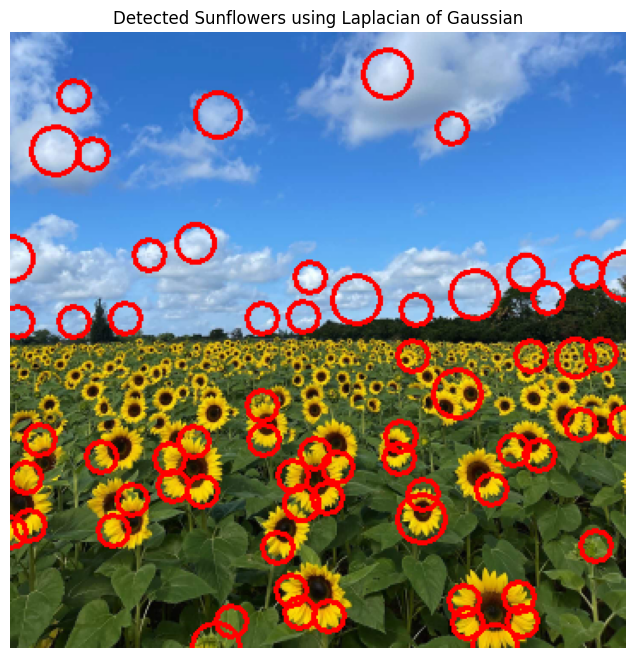

In [37]:
# Create a copy of the original image to draw on
image_with_circles = image.copy()

# Loop over the detected blobs and draw circles
for blob in blobs:
    y, x, r = blob
    # Draw the circle on the image
    cv2.circle(image_with_circles, (int(x), int(y)), int(r), (0, 0, 255), 2) # Red circle with thickness 2

# Display the final image with circles
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(image_with_circles, cv2.COLOR_BGR2RGB))
plt.title('Detected Sunflowers using Laplacian of Gaussian')
plt.axis('off')
plt.show()